In [7]:
import json
from datetime import datetime
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

E_HULL_MAX = 0.05  # ev/atom: keep materials with 0  less or equal to energy_above_hull less or equal to this value
FORMATION_ENERGY_MAX = 0.0   # ev/atom: keep materials with formation energy less than zero

HERE = Path.cwd()
candidates = [
    HERE / "data",
    HERE,
    HERE / "notebook" / "data" / "data",
    HERE / "nootebook" / "data",

]
DATA_DIR = next((p for p in candidates if (p / "RawData.csv").exists()), None)
assert DATA_DIR is not None, "RawData.csv not found. Run the extraction  notebook first."

RAW_PATH = DATA_DIR / "RawData.csv"
OUT_PATH = DATA_DIR / "Stability.csv"
FIG_DIR = DATA_DIR.parent / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("Input:", RAW_PATH)
print("Output:", OUT_PATH)


Input: c:\Users\solom\Desktop\SemiconductorProject\notebook\data\data\RawData.csv
Output: c:\Users\solom\Desktop\SemiconductorProject\notebook\data\data\Stability.csv


In [2]:
df = pd.read_csv(RAW_PATH)
print("RawData shape:", df.shape)
df.head()

RawData shape: (76824, 16)


,formula,elements,nelements,nsites,volume,density,crystal_system,space_group,formation_energy_per_atom,energy_above_hull,is_stable,band_gap,cbm,vbm,is_gap_direct,theoretical
0,Ac2O3,Ac_O,2,5,91.511224,9.109130,Trigonal,P-3m1,-3.737668,0.000000,True,3.5219,8.1120,4.5901,False,False
1,Ac2S3,Ac_S,2,40,1118.407852,6.535149,Tetragonal,I-42d,-2.493064,0.000000,True,2.2729,7.0869,4.8140,False,True
2,Ac2S3,Ac_S,2,10,328.464893,5.562971,Trigonal,R-3c,-2.440364,0.052700,False,3.0275,5.9344,2.9069,False,True
3,AcAgTe2,Ac_Ag_Te,3,4,122.518406,7.997421,Cubic,Fm-3m,-0.996232,0.253251,False,0.0748,6.0799,6.0051,False,True
4,AcAlO3,Ac_Al_O,3,5,57.451413,8.728230,Cubic,Pm-3m,-3.690019,0.000000,True,4.1024,10.9060,6.8036,True,True


In [8]:
df["is_stable"] = df["is_stable"].astype(str).str.strip().str.lower().eq("true")

print("is_stable (on the hull) count:")
print(df["is_stable"].value_counts().rename({True: "stable", False: "not stable"}))
print()
print("Missing the energy_above_hull        :", int(df["energy_above_hull"].isna().sum()))
print("Missing the formation_energy_per_atom:", int(df["formation_energy_per_atom"].isna().sum()))
print()
print("How many materials survive each E_hull cut-off:")
for t in [0.0, 0.03, 0.05, 0.08, 0.10]:
    n = int((df["energy_above_hull"] <= t + 1e-9).sum())
    print(f" E_hull <= {t: .2f} eV/atom : {n:,} ({n / len(df):.1%})")
print()
print("Formation Energy < 0 (all rows):", int((df["formation_energy_per_atom"] < 0).sum()))
print("Formation Energy = 0 (elements):", int((df["formation_energy_per_atom"].abs() < 1e-6).sum())) 
print("Formation Energy > 0           :", int((df["formation_energy_per_atom"] > 0).sum()))



is_stable (on the hull) count:
is_stable
not stable    62329
stable        14495
Name: count, dtype: int64

Missing the energy_above_hull        : 0
Missing the formation_energy_per_atom: 0

How many materials survive each E_hull cut-off:
 E_hull <=  0.00 eV/atom : 14,495 (18.9%)
 E_hull <=  0.03 eV/atom : 31,139 (40.5%)
 E_hull <=  0.05 eV/atom : 38,610 (50.3%)
 E_hull <=  0.08 eV/atom : 48,449 (63.1%)
 E_hull <=  0.10 eV/atom : 53,914 (70.2%)

Formation Energy < 0 (all rows): 74436
Formation Energy = 0 (elements): 13
Formation Energy > 0           : 2375


In [9]:
ehull = df["energy_above_hull"]
fe = df["formation_energy_per_atom"]

step1 = ehull.notna() & ( ehull < E_HULL_MAX + 1e-9)
step2 = step1 & fe.notna() & ( fe < FORMATION_ENERGY_MAX)

print("Screening funnel")
print(f" RawData                            : {len(df): ,}")
print(f" after stability (E_hull <= {E_HULL_MAX}) : {int(step1.sum()):,}")
print("  after formation energy < {FORMATION_ENERGY_MAX}       : {int(step2.sum()):,}")
print(f" removed by formation energy      : {int(step1.sum() - step2.sum()):,}")

stable_df = df[step2].copy().reset_index(drop = True)
stable_df["stability_class"] = ["stable" if e < 1e-6 else "near-stable" for e in stable_df["energy_above_hull"]]

rule = (f"0 <= energy_above_hull <= {E_HULL_MAX} eV/atom"
      f" AND formation_energy_per_atom {FORMATION_ENERGY_MAX} eV/atom")
removed = len(df) - len(stable_df)

print()
print("Rule applied:", rule)
print(f"kept: {len(stable_df):,} ({len(stable_df) / len(df):.1%}) | Removed: {removed:,}")
print(stable_df["stability_class"].value_counts())


Screening funnel
 RawData                            :  76,824
 after stability (E_hull <= 0.05) : 38,610
  after formation energy < {FORMATION_ENERGY_MAX}       : {int(step2.sum()):,}
 removed by formation energy      : 144

Rule applied: 0 <= energy_above_hull <= 0.05 eV/atom AND formation_energy_per_atom 0.0 eV/atom
kept: 38,466 (50.1%) | Removed: 38,358
stability_class
near-stable    23983
stable         14483
Name: count, dtype: int64


In [10]:
stable_df.to_csv(OUT_PATH, index=False)

summary = {
    "saved_at": datetime.now().isoformat(timespec="seconds"),
    "input_file": RAW_PATH.name,
    "output_file": OUT_PATH.name,
    "rule": rule,
    "energy_above_hull": E_HULL_MAX,
    "formation_energy_max_per_atom": FORMATION_ENERGY_MAX,
    "rows_in": int(len(df)),
    "after_stability": int(step1.sum()),
    "after_formation_energy": int(step2.sum()),
    "row_kept": int(len(stable_df)),
    "row_removed": int(removed),
    "stable": int((stable_df["stability_class"] =="stable").sum()),
    "near_stable": int((stable_df["stability_class"] == "near-stable").sum()),
    "kept_with_cbm_and_vbm": int(stable_df[["cbm", "vbm"]].notna().all(axis=1).sum()),
}
(DATA_DIR / f"{OUT_PATH.stem}_summary.json").write_text(json.dumps(summary, indent=2))
print("Saved:", OUT_PATH)
print(json.dumps(summary, indent=2))

Saved: c:\Users\solom\Desktop\SemiconductorProject\notebook\data\data\Stability.csv
{
  "saved_at": "2026-10-26T14:19:33",
  "input_file": "RawData.csv",
  "output_file": "Stability.csv",
  "rule": "0 <= energy_above_hull <= 0.05 eV/atom AND formation_energy_per_atom 0.0 eV/atom",
  "energy_above_hull": 0.05,
  "formation_energy_max_per_atom": 0.0,
  "rows_in": 76824,
  "after_stability": 38610,
  "after_formation_energy": 38466,
  "row_kept": 38466,
  "row_removed": 38358,
  "stable": 14483,
  "near_stable": 23983,
  "kept_with_cbm_and_vbm": 38466
}


kept materials by theoretical flag:
theoretical
True     20713
False    17753
Name: count, dtype: int64

       formation_energy_per_atom  energy_above_hull   band_gap        cbm  \
count                  38466.000          38466.000  38466.000  38466.000   
mean                      -2.098              0.013      2.176      3.929   
std                        0.878              0.016      1.320      1.825   
min                       -4.389              0.000      0.010     -6.446   
25%                       -2.725              0.000      1.067      2.793   
50%                       -2.251              0.006      2.111      3.960   
75%                       -1.478              0.025      3.188      5.100   
max                       -0.000              0.050      5.000     12.816   

             vbm  
count  38466.000  
mean       1.753  
std        1.928  
min       -6.519  
25%        0.559  
50%        1.724  
75%        2.956  
max       11.638  


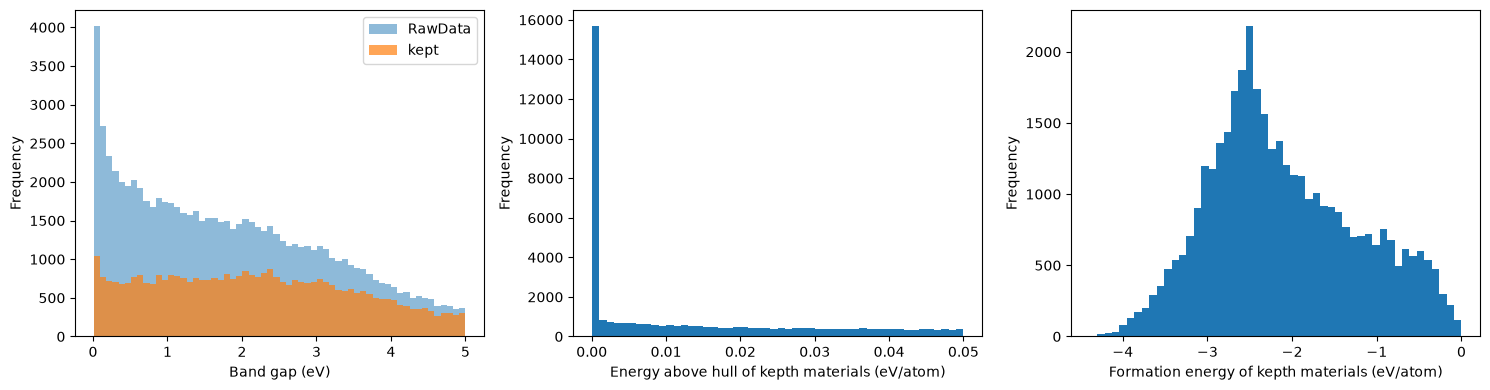

In [11]:
print("kept materials by theoretical flag:")
print(stable_df["theoretical"].value_counts(dropna=False))
print()
print(stable_df[["formation_energy_per_atom", "energy_above_hull", "band_gap", "cbm", "vbm"]].describe().round(3))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
df["band_gap"].plot.hist(bins=60, ax=axes[0], alpha =0.5, label="RawData")
stable_df["band_gap"].plot.hist(bins=60, ax=axes[0], alpha=0.7, label="kept")
axes[0].set_xlabel("Band gap (eV)"); axes[0].legend()
stable_df["energy_above_hull"].plot.hist(bins=50, ax=axes[1])
axes[1].set_xlabel("Energy above hull of kepth materials (eV/atom)")
stable_df["formation_energy_per_atom"].plot.hist(bins=50, ax=axes[2])
axes[2].set_xlabel("Formation energy of kepth materials (eV/atom)")
plt.tight_layout()
plt.savefig(FIG_DIR / "stability_screening.png", dpi=200)
plt.show()
